In [29]:
# 3-class classification of FGL sources for astro.ML workshop
import numpy as np
import pandas as pd
from matplotlib import pyplot
import os


from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve, roc_auc_score

import sys
if '../lib/' not in sys.path:
    sys.path.append('../lib/')
import dio3
import multi_fgl_utils as util
import plot_util as putil

In [30]:
if 1:
    import importlib
    importlib.reload(util);


In [31]:
folder = '../data_out/'
folder_in = '../data_in/'

xdf_fn = folder + 'xdf.csv'
xdf = pd.read_csv(xdf_fn, index_col=0)
featrues = [name for name in xdf.columns if name != 'class']
ns = len(xdf)

fn = folder_in + '4FGL-DR3_categories.csv'
classes_df = pd.read_csv(fn)
assoc_classes = [cl for cl in classes_df['Associated'] if not cl.startswith('un')]
nsrc_dict = {cl:np.sum(xdf['class'] == cl) for cl in assoc_classes}

alg0 = 'RF'
pars_dict = {'RF':10, 'BDT':9, 'NN':15, "LR":1000}
#pars_dict = {'RF':3, 'BDT':9, 'NN':5, "LR":1000}
pars_names = {'RF':'Depth', 'BDT':'Depth', 'NN':'Neurons', 
              'LR':'Iterations'}
pars_names_labels = {'RF':'Tree depth', 'BDT':'Tree depth', 'NN':'Number of neurons', 
              'LR':'Iterations'}

titles_dict = {'RF':'Random forest', 'BDT':'Boosted decision trees', 
               'NN':'Neural network', "LR":'Logistic regression'}

test_frac = .3
test_meta_pars = 1

save_plots = 1
plots_folder = '../plots/'
plots_folder_proceed = '../../fermi_multiclass_papers/astro_ml_proceedings/overleaf_git/plots/'

In [32]:
print(assoc_classes)

['gc', 'psr', 'msp', 'pwn', 'snr', 'spp', 'glc', 'sfr', 'hmb', 'lmb', 'bin', 'nov', 'bll', 'fsrq', 'rdg', 'agn', 'ssrq', 'css', 'bcu', 'nlsy1', 'sey', 'sbg', 'gal']


In [33]:
nsrc_dict

{'gc': 1,
 'psr': 137,
 'msp': 155,
 'pwn': 19,
 'snr': 43,
 'spp': 114,
 'glc': 35,
 'sfr': 5,
 'hmb': 11,
 'lmb': 8,
 'bin': 7,
 'nov': 4,
 'bll': 1456,
 'fsrq': 794,
 'rdg': 45,
 'agn': 9,
 'ssrq': 2,
 'css': 5,
 'bcu': 1493,
 'nlsy1': 8,
 'sey': 2,
 'sbg': 8,
 'gal': 6}

In [34]:
# hand-made classification
tree_cat_dict = {}
tree_cat_dict['00'] = ['bll', 'fsrq', 'rdg', 'agn', 'ssrq', 'css', 'bcu', 'nlsy1', 'sey']
tree_cat_dict['010'] = ['psr', 'msp',]
tree_cat_dict['011'] = ['gc', 'pwn', 'snr', 'spp', 'glc', 'sfr', 'hmb', 'lmb', 'bin', 'nov', 'sbg', 'gal']
label_dict = {'00': 'AGNs', '01': 'Galactic', '010':'Pulsars', '011':'Galactic non-pulsar'}
cat_tree = list(tree_cat_dict.keys())
subtree = ['0']
horiz_trees = []
while util.max_node_length(subtree) < util.max_node_length(cat_tree):
    subtree = util.get_children(subtree, cat_tree)
    horiz_trees.append(subtree)

In [35]:
nav = 1
pred_dict = {}
rel_dict = {}
pgrid = np.arange(0, 1.000001, 0.1)
level0 = 0
max_level = util.max_node_length(cat_tree) - 1
parents = horiz_trees[level0]
class1 = '01'
pred_test = {}
y_test_dict = {}
for level, subtree in enumerate(horiz_trees[level0:max_level]):
    print(level)
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict)
    nodes = subtree #list(cut_subtree.keys())

    ys = np.zeros(ns, dtype='<U6')
    if level == level0:
        ys_true = ys
    clf_mask = np.zeros(ns, dtype=bool)
    #cls_masks_all = []
    for key, cls in cut_subtree.items():
        cls_mask = util.get_cl_mask(cls, xdf)
        #cls_masks_all.append(cls_mask)
        ys[cls_mask] = key
        clf_mask[cls_mask] = True
    #cls_masks_all = np.array(cls_masks_all)
    
    X = xdf[featrues][clf_mask]
    y = ys[clf_mask]

    for j in range(nav):
        clf = util.get_classifier(alg0, pars_dict[alg0])
        X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_frac, random_state=j)
        clf.fit(X_train, y_train)
    
        pred_test_loc = clf.predict_proba(X_test).T

        inds = [list(clf.classes_).index(node) for node in nodes]
        pred_test[level] = np.array([pred_test_loc[ind] for ind in inds])
        y_test_dict[level] = y_test
        
        
        # at the moment implemented only for nav = 1
        class1_nodes = util.all_leaf_children(subtree, class1)
        class1_inds = [nodes.index(node) for node in class1_nodes]
        pred_dict[level] = pd.DataFrame(index=X_test.index)
        pred_dict[level]['y_pred'] = np.sum(pred_test[level][class1_inds], axis=0)
        pred_dict[level]['y_true'] = np.array([y[:len(class1)] == class1 for y in y_test], dtype=int)
        
        rel_dict[level] = {}
        for i, node in enumerate(nodes):
            y_true = np.array(y_test == node, dtype=int)
            y_prob = pred_test[level][i]
            rel_dict[level][node] = util.get_reliability(y_true, y_prob, pgrid)


0
1


# Test meta-parameters

In [36]:

if test_meta_pars:
    scores_dict = {}
    for level, subtree in enumerate(horiz_trees[level0:max_level]):
        print(level)
        scores_dict[level] = {}
        scores = scores_dict[level]
        cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict)
        nodes = subtree #list(cut_subtree.keys())

        ys = np.zeros(ns, dtype='<U6')
        if level == level0:
            ys_true = ys
        clf_mask = np.zeros(ns, dtype=bool)
        #cls_masks_all = []
        for key, cls in cut_subtree.items():
            cls_mask = util.get_cl_mask(cls, xdf)
            #cls_masks_all.append(cls_mask)
            ys[cls_mask] = key
            clf_mask[cls_mask] = True
        #cls_masks_all = np.array(cls_masks_all)

        X = xdf[featrues][clf_mask]
        y = ys[clf_mask]
        par_values = np.arange(3, 20, 2)
        scan_pars_dict = {alg0:par_values}
        # scan complexity parameter

        nav = 10
        algs = [alg0]
        for alg in algs:
            print(alg)
            scores[alg] = np.zeros_like(scan_pars_dict[alg], dtype=float)
            scores[alg+'_pars'] = list(scan_pars_dict[alg])
            for i, par in enumerate(scan_pars_dict[alg]):
                print(par)
                clf = util.get_classifier(alg, par)
                for j in range(nav):
                    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_frac, random_state=j)
                    clf.fit(X_train, y_train)
                    scores[alg][i] += clf.score(X_test, y_test) / nav
                print('score: %.5f' % scores[alg][i])


0
RF
3
score: 0.94683
5
score: 0.95256
7
score: 0.95553
9
score: 0.95606
11
score: 0.95774
13
score: 0.95614
15
score: 0.95645
17
score: 0.95812
19
score: 0.95835
1
RF
3
score: 0.92853
5
score: 0.93776
7
score: 0.93928
9
score: 0.93913
11
score: 0.93966
13
score: 0.93921
15
score: 0.93898
17
score: 0.94043
19
score: 0.93860


In [37]:
#clf.out_activation_

save figure to file: ../plots/RF_accuracy_scan.pdf
save figure to file: ../../fermi_multiclass_papers/astro_ml_proceedings/overleaf_git/plots/RF_accuracy_scan.pdf


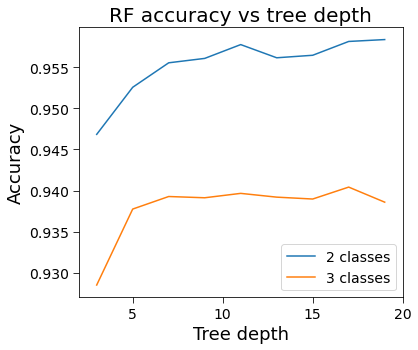

In [38]:
putil.setup_figure_pars()
if test_meta_pars:
    fig_size =  [6, 5]
    pyplot.rcParams['figure.figsize'] =  fig_size
    pyplot.rcParams['figure.subplot.left'] = 0.2
    pyplot.rcParams['axes.titlesize'] = 20

    pyplot.figure()
    for level in range(level0, max_level):
        pyplot.plot(par_values, scores_dict[level][alg0], 
                    label='%i classes' % len(horiz_trees[level]))
    pyplot.legend()
    pyplot.xlim(2, 20)
    pyplot.xlabel(pars_names_labels[alg0])
    pyplot.ylabel('Accuracy')
    pyplot.title('%s accuracy vs %s' % (alg0, pars_names_labels[alg0].lower()))
    if save_plots:
        fn = '%s_accuracy_scan.pdf' % alg0
        print('save figure to file: %s' % (plots_folder + fn))
        pyplot.savefig(plots_folder + fn)
        if os.path.isdir(plots_folder_proceed):
            print('save figure to file: %s' % (plots_folder_proceed + fn))
            pyplot.savefig(plots_folder_proceed + fn)


# ROC curves

save figure to file: ../plots/ROC_3class_RF_depth10.pdf
save figure to file: ../../fermi_multiclass_papers/astro_ml_proceedings/overleaf_git/plots/ROC_3class_RF_depth10.pdf


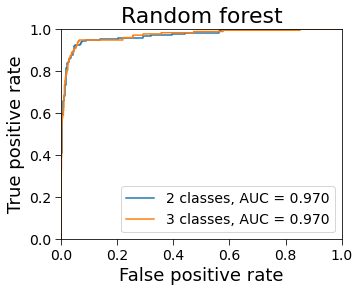

In [11]:
putil.setup_figure_pars()
fig_size =  [5, 4]
pyplot.rcParams['figure.figsize'] =  fig_size
left0 = pyplot.rcParams['figure.subplot.left']
bottom0 = pyplot.rcParams['figure.subplot.bottom']
pyplot.rcParams['figure.subplot.left'] = 0.17
pyplot.rcParams['figure.subplot.bottom'] = 0.17


pyplot.figure()
for level in pred_dict.keys():
    y_score = pred_dict[level]['y_pred']
    y_true = pred_dict[level]['y_true']
    fpr, tpr, thres = roc_curve(y_true, y_score)
    auc = roc_auc_score(y_true, y_score)
    pyplot.plot(fpr, tpr, label='%i classes, AUC = %.3f' % \
                (len(horiz_trees[level]), auc))
    pyplot.xlim(0.0, 1)
    pyplot.ylim(0.0, 1)
    pyplot.legend(loc='lower right')
    pyplot.xlabel('False positive rate')
    pyplot.ylabel('True positive rate')
pyplot.title(titles_dict[alg0])
if save_plots:
    fn = 'ROC_3class_%s_%s%i.pdf' % (alg0, pars_names[alg0].lower(), pars_dict[alg0])
    print('save figure to file: %s' % (plots_folder + fn))
    pyplot.savefig(plots_folder + fn)
    if os.path.isdir(plots_folder_proceed):
        print('save figure to file: %s' % (plots_folder_proceed + fn))
        pyplot.savefig(plots_folder_proceed + fn)
        

pyplot.rcParams['figure.subplot.left'] = left0
pyplot.rcParams['figure.subplot.bottom'] = bottom0


# Reliability diagrams

0
AGNs 3814
Galactic 553
1
AGNs 3814
Pulsars 292
Galactic non-pulsar 261
save figure to file: ../plots/reliability_diag_3class_RF_depth10.pdf
save figure to file: ../../fermi_multiclass_papers/astro_ml_proceedings/overleaf_git/plots/reliability_diag_3class_RF_depth10.pdf


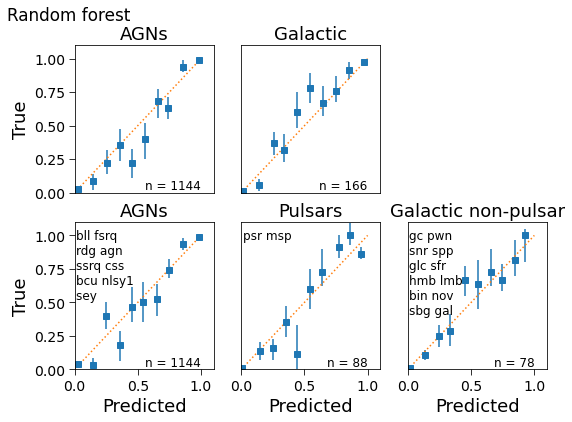

In [12]:
putil.setup_figure_pars()
max_level = 2
ncols = len(horiz_trees[max_level - 1])
nrows = max_level - level0

fig_height = 2 * nrows + 2   # height in inches
fig_width = 2 * ncols + 2  # width in inches

fig_size =  [fig_width, fig_height]
pyplot.rcParams['figure.figsize'] =  fig_size
pyplot.rcParams['axes.titlesize'] =  18

fig = pyplot.figure()
for level, subtree in enumerate(horiz_trees[level0:max_level]):
    print(level)
    cut_subtree = util.sub_tree2tree_cat_dict(subtree, cat_tree, tree_cat_dict)
    nodes = list(cut_subtree.keys())

    xshift = 0
    for i, node in enumerate(nodes):
        nsrc = np.sum([nsrc_dict[cl] for cl in cut_subtree[node]])
        print(label_dict[node], nsrc)
        ind = level * ncols + xshift + 1
        ax = pyplot.subplot(nrows, ncols, ind)
        if level < max_level - 1:
            xshift += len(util.get_subtree(node, horiz_trees[max_level - 1]))
        else:
            xshift += 1
            
        xs = rel_dict[level][node]['prob_pred']
        ys = rel_dict[level][node]['prob_true']
        err = rel_dict[level][node]['err_true']
        pyplot.errorbar(xs, ys, yerr=err, marker='s', ls='')
        pyplot.plot([0,1], [0,1], ls=':')
        
        
        if i == 0:
            pyplot.ylabel('True')
        else:
            ax.axes.yaxis.set_visible(False)
        if level == max_level - 1:
            pyplot.xlabel('Predicted')
            text = ''
            for i, cls in enumerate(cut_subtree[node]):
                text += '%s ' % cls
                if i < len(cut_subtree[node]) - 1 and i % 2 != 0:
                    text += '\n'
            ax.text(0.01, 1.05, text, fontsize=12, horizontalalignment='left', verticalalignment='top')
        else:
            ax.axes.xaxis.set_visible(False)
        ax.text(1., 0.0, 'n = %i' % np.round(nsrc * test_frac), 
                fontsize=12, horizontalalignment='right', verticalalignment='bottom')
        #pyplot.title('Level %i, %s' % (level, cut_subtree[node]))
        # pyplot.title('Level %i, %s' % (level, node))
        pyplot.xlim(0, 1.1)
        pyplot.ylim(0, 1.1)
        pyplot.title('%s' % (label_dict[node]))
fig.suptitle(titles_dict[alg0], x=0.12, y=0.99)

if save_plots:
    fn = 'reliability_diag_3class_%s_%s%i.pdf' % \
            (alg0, pars_names[alg0].lower(), pars_dict[alg0])
    print('save figure to file: %s' % (plots_folder + fn))
    pyplot.savefig(plots_folder + fn)
    if os.path.isdir(plots_folder_proceed):
        print('save figure to file: %s' % (plots_folder_proceed + fn))
        pyplot.savefig(plots_folder_proceed + fn)


In [13]:
3814/292., 3814/261.

(13.061643835616438, 14.613026819923371)

# Precision and recall

In [14]:
# plot precision and recall for Galactic sources (subclasses of 01)
# precision = true pred / pred
# recall = true pred / true
#pred_test.keys()
thres = np.arange(0.05, 0.9501, 0.05)
pr_dict = {}
for level, subtree in enumerate(horiz_trees[level0:max_level]):
    print(level)
    pr_dict[level] = {}
    class1_nodes = util.all_leaf_children(subtree, class1)
    y_pred_parent = 0.
    y_true_parent = False
    for node in class1_nodes:
    #for node in subtree:
        ind = subtree.index(node)
        y_pred = pred_test[level][ind]
        y_pred_parent += y_pred
        y_true = y_test_dict[level] == node
        y_true_parent |= y_true
        pr_df = pd.DataFrame(index=thres, columns=['prec', 'recall'], data=-1.)
        for i, th in enumerate(thres):
            y_pred_th = y_pred > th
            if np.sum(y_pred_th) > 0:
                pr_df['prec'][th] = np.sum(y_pred_th & y_true) / np.sum(y_pred_th)
            pr_df['recall'][th] = np.sum(y_pred_th & y_true) / np.sum(y_true)
        pr_dict[level][node] = pr_df
    
    # calculate for the parent node
    pr_df = pd.DataFrame(index=thres, columns=['prec', 'recall'], data=-1.)
    for i, th in enumerate(thres):
        y_pred_th = y_pred_parent > th
        if np.sum(y_pred_th) > 0:
            pr_df['prec'][th] = np.sum(y_pred_th & y_true_parent) / np.sum(y_pred_th)
        pr_df['recall'][th] = np.sum(y_pred_th & y_true_parent) / np.sum(y_true_parent)
    pr_dict[level][class1] = pr_df

0
1


save figure to file: ../plots/prec_recall_3class_RF_level0_depth10.pdf
save figure to file: ../../fermi_multiclass_papers/astro_ml_proceedings/overleaf_git/plots/prec_recall_3class_RF_level0_depth10.pdf
save figure to file: ../plots/prec_recall_3class_RF_level1_depth10.pdf
save figure to file: ../../fermi_multiclass_papers/astro_ml_proceedings/overleaf_git/plots/prec_recall_3class_RF_level1_depth10.pdf


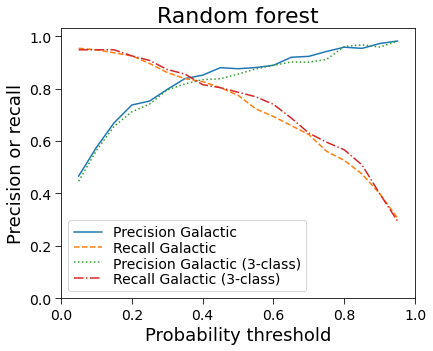

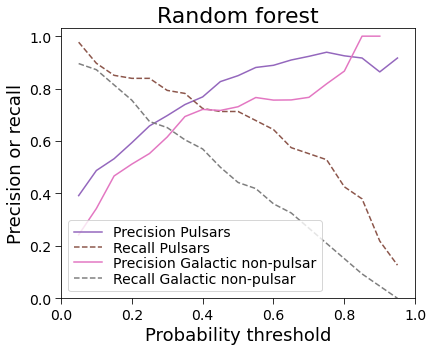

In [15]:
putil.setup_figure_pars()
fig_size =  [6, 5]
pyplot.rcParams['figure.figsize'] =  fig_size
#pyplot.rcParams['figure.subplot.left'] = 0.17
#pyplot.rcParams['figure.subplot.bottom'] = 0.17


cs = pyplot.rcParams['axes.prop_cycle'].by_key()['color']
ic = 0
for level, subtree in enumerate(horiz_trees[level0:max_level]):
    pyplot.figure()
    class1_nodes = util.all_leaf_children(subtree, class1)
    for node in class1_nodes:
        ys = pr_dict[level][node]['prec']
        zero_mask = (ys >= 0.)
        label = 'Precision %s' % (label_dict[node])
        pyplot.plot(thres[zero_mask], ys[zero_mask], c=cs[ic], 
                    label=label)
        #print(label)
        #print(ys)

        ic += 1
        ys = pr_dict[level][node]['recall']
        zero_mask = (ys >= 0.)
        pyplot.plot(thres[zero_mask], ys[zero_mask], c=cs[ic], 
                    ls='--', label='Recall %s' % (label_dict[node]))
        ic += 1
        
    if level == 0 and node == class1:
        # compare the parent node with sum of children
        for lvl in [1]:
            ys = pr_dict[lvl][node]['prec']
            zero_mask = (ys >= 0.)
            pyplot.plot(thres[zero_mask], ys[zero_mask], ls=':', c=cs[ic],
                        label='Precision %s (3-class)' % (label_dict[node]))
            ic += 1
            ys = pr_dict[lvl][node]['recall']
            zero_mask = (ys >= 0.)
            pyplot.plot(thres[zero_mask], ys[zero_mask], ls='-.', c=cs[ic], 
                        label='Recall %s (3-class)' % (label_dict[node]))
            ic += 1

    #pyplot.plot([0.5, 0.5], [0, 1], ls=':') 
    #pyplot.grid()
    pyplot.legend(labelspacing=0.1, fontsize=14)
    pyplot.xlabel('Probability threshold')
    pyplot.ylabel('Precision or recall')
    pyplot.xlim(0, 1)
    pyplot.ylim(0, 1.03)
    pyplot.title(titles_dict[alg0])
    if save_plots:
        fn = 'prec_recall_3class_%s_level%i_%s%i.pdf' % \
                    (alg0, level, pars_names[alg0].lower(), pars_dict[alg0])
        print('save figure to file: %s' % (plots_folder + fn))
        pyplot.savefig(plots_folder + fn)
        if os.path.isdir(plots_folder_proceed):
            print('save figure to file: %s' % (plots_folder_proceed + fn))
            pyplot.savefig(plots_folder_proceed + fn)
            
            


In [16]:
level = 1
cthres = 0.5
for level in [0, 1]:
    print('Level', level)
    for node in pr_dict[level].keys():
        print(label_dict[node])
        print(pr_dict[level][node].loc[cthres])
        print()

Level 0
Galactic
prec      0.875817
recall    0.774566
Name: 0.5, dtype: float64

Level 1
Pulsars
prec      0.849315
recall    0.712644
Name: 0.5, dtype: float64

Galactic non-pulsar
prec      0.730769
recall    0.441860
Name: 0.5, dtype: float64

Galactic
prec      0.855346
recall    0.786127
Name: 0.5, dtype: float64

